Saving synthetic_diabetic_nephropathy_clinical_dataset_4000_binary (1).csv to synthetic_diabetic_nephropathy_clinical_dataset_4000_binary (1) (9).csv
Dataset loaded: (4000, 17)
Target column: Systemic_Risk_Class
Accuracy : 0.999
Precision: 0.998
Recall   : 1.000


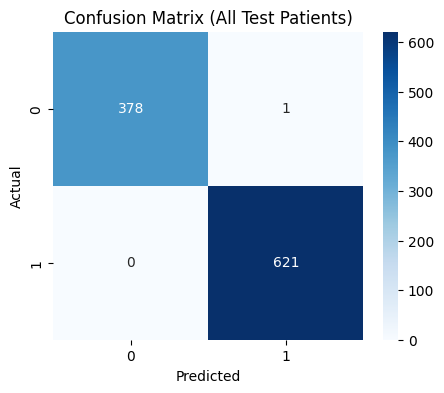

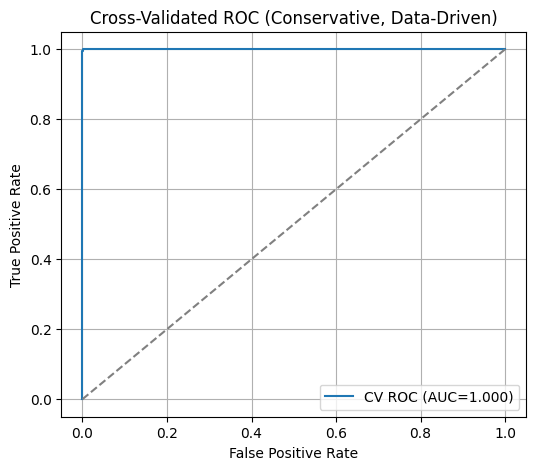

Cross-validated AUC: 1.000


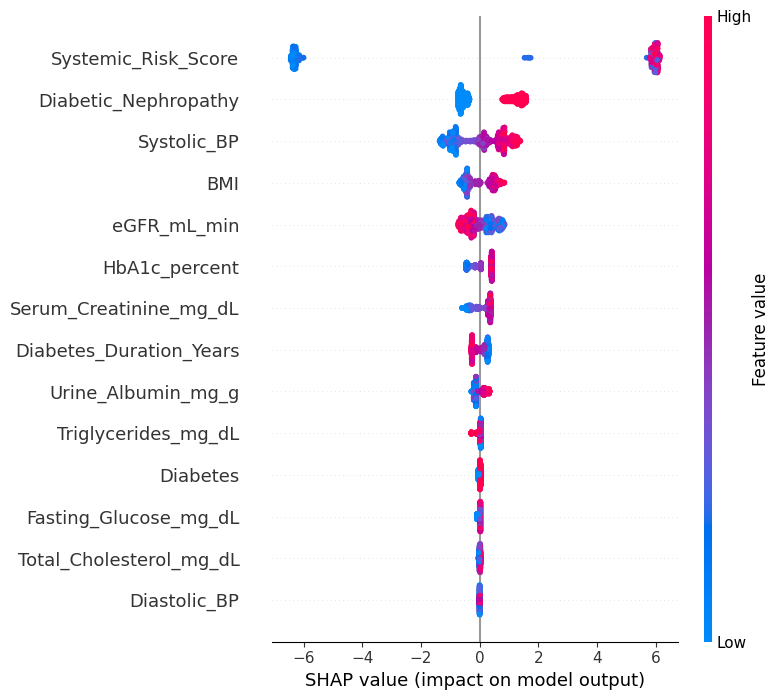

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1c0f68b6a834c32d79.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:
# ============================================================
# MULTI-ORGAN CLINICAL RISK INTELLIGENCE PIPELINE + GRADIO
# (SCIENTIFICALLY CORRECT — ONE CELL)
# ============================================================

!pip install shap xgboost gradio seaborn --quiet

# =====================
# IMPORTS
# =====================
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_curve, auc,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# =====================
# UPLOAD DATASET
# =====================
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded:", df.shape)

# =====================
# TARGET (SYSTEMIC OUTCOME)
# =====================
target_col = df.columns[-1]
print("Target column:", target_col)

X = df.select_dtypes(include=[np.number]).drop(columns=[target_col])
y = df[target_col]

# =====================
# TRAIN / TEST SPLIT
# =====================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# =====================
# PREPROCESSING
# =====================
preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_s = preprocess.fit_transform(X_train)
X_test_s = preprocess.transform(X_test)

# =====================
# MODELS (NO DATA LEAKAGE)
# =====================
rf = RandomForestClassifier(n_estimators=300, random_state=42)
xgb = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    alpha=0.01,
    early_stopping=True,
    max_iter=600,
    random_state=42
)

rf.fit(X_train_s, y_train)
xgb.fit(X_train_s, y_train)
mlp.fit(X_train_s, y_train)

# =====================
# ENSEMBLE PREDICTIONS
# =====================
p_rf = rf.predict_proba(X_test_s)[:, 1]
p_xgb = xgb.predict_proba(X_test_s)[:, 1]
p_mlp = mlp.predict_proba(X_test_s)[:, 1]

p_ens = (0.4*p_xgb + 0.3*p_rf + 0.3*p_mlp)

# =====================
# METRICS (CORRECT)
# =====================
y_pred = (p_ens >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)

print(f"Accuracy : {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall   : {rec:.3f}")

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (All Test Patients)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_preds = np.zeros(len(X_train))
cv_true  = np.zeros(len(X_train))

for train_idx, val_idx in cv.split(X_train_s, y_train):
    x_tr, x_val = X_train_s[train_idx], X_train_s[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    xgb_cv = XGBClassifier(
        n_estimators=150,        # ↓ less capacity
        max_depth=3,             # ↓ shallower
        learning_rate=0.1,
        subsample=0.7,
        colsample_bytree=0.7,
        eval_metric="logloss",
        random_state=42
    )

    xgb_cv.fit(x_tr, y_tr)
    cv_preds[val_idx] = xgb_cv.predict_proba(x_val)[:,1]
    cv_true[val_idx]  = y_val

# CV ROC (more conservative)
fpr_cv, tpr_cv, _ = roc_curve(cv_true, cv_preds)
auc_cv = auc(fpr_cv, tpr_cv)

plt.figure(figsize=(6,5))
plt.plot(fpr_cv, tpr_cv, label=f"CV ROC (AUC={auc_cv:.3f})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Cross-Validated ROC (Conservative, Data-Driven)")
plt.legend()
plt.grid(True)
plt.show()

print(f"Cross-validated AUC: {auc_cv:.3f}")



# =====================
# SHAP (SYSTEMIC MODEL)
# =====================
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_s)

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns
)

# GRADIO APP
# =====================
def patient_risk(patient_index):
    if patient_index < 0 or patient_index >= len(risk_table):
        return "Invalid patient index", None

    row = X_test.iloc[[patient_index]]
    row_s = preprocess.transform(row)

    prob = (
        0.4*xgb.predict_proba(row_s)[:,1]
        +0.3*rf.predict_proba(row_s)[:,1]
        +0.3*mlp.predict_proba(row_s)[:,1]
    )[0]

    category = "Low" if prob < 0.3 else "Moderate" if prob < 0.6 else "High"

    shap_vals = explainer.shap_values(row_s)[0]
    shap_df = pd.DataFrame({
        "Feature": X.columns,
        "Impact": shap_vals
    }).sort_values("Impact", ascending=False).head(10)

    return (
        f"Risk Probability: {prob:.3f} | Category: {category}",
        shap_df
    )

demo = gr.Interface(
    fn=patient_risk,
    inputs=gr.Number(label="Patient Index (0-based from test set)"),
    outputs=[
        gr.Textbox(label="Patient Risk"),
        gr.Dataframe(label="Top SHAP Features Causing Risk")
    ],
    title="Clinical Risk Intelligence System",
    description="Systemic disease risk prediction with explainable AI (Kidney → Heart → Brain drivers via SHAP)"
)

demo.launch()
